# DAY3 실습 01 — 표본과 추정

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

| 열 | 뜻 |
|---|---|
| `UDI` | 기록 번호 (측정값이 아니다) |
| `Type` | 제품 품질 유형 L · M · H |
| `Torque [Nm]` | 토크 (N·m) |
| `Rotational speed [rpm]` | 회전속도 (rpm, 분당 회전수) |
| `Machine failure` | 고장 여부 (0 = 정상, 1 = 고장) |

**질문** : 운전 기록 일부(표본)만 보고, 전체 기록의 평균 토크를 얼마로 추정할 수 있는가? 그 추정은 얼마나 정확한가?

**실습 전제** : AI4I 10,000건 전체를 **실습용 모집단**으로 둔다. 실제 분석에서는 모집단 전체를 알 수 없어 모평균도 모른다. 이 자료는 모평균을 알고 있으므로, 표본으로 구한 값을 모평균과 비교해 추정이 얼마나 맞는지 알 수 있다.

In [ ]:
# 데이터 확인 : 행·열 수, 토크 결측, 기록 번호 중복
print("행·열:", data.shape)
print("토크 결측:", data["Torque [Nm]"].isna().sum())
print("UDI 중복:", data["UDI"].duplicated().sum())

행·열: (10000, 14)
토크 결측: 0
UDI 중복: 0


## 1. 모집단과 표본

**모집단**(Population)은 알고 싶은 대상 전체이고, **표본**(Sample)은 모집단에서 실제로 조사한 일부다.

**모수**(Parameter)는 모집단의 특성을 나타내는 값이고, **통계량**(Statistic)은 표본에서 계산한 값이다. 모집단 전체를 알 수 없으므로 통계량으로 모수를 추정한다.

| 구분 | 모수 (모집단) | 통계량 (표본) | 읽는 법 |
|---|---|---|---|
| 평균 | μ 모평균 | x̄ 표본평균 | 뮤 / 엑스바 |
| 비율 | p 모비율 | p̂ 표본비율 | 피 / 피햇 |
| 표준편차 | σ 모표준편차 | s 표본표준편차 (분모 n − 1) | 시그마 / 에스 |

모수는 하나로 정해진 값이고, 통계량은 표본을 다시 뽑으면 달라진다.

공식 문서 : [NIST : What is a population, sample?](https://www.itl.nist.gov/div898/handbook/prc/section1/prc11.htm)

In [ ]:
# [예제] 공정시간 10개로 된 모집단에서 4개씩 뽑은 표본의 평균 (단위 : 분)
process_time = pd.Series([48, 52, 47, 55, 50, 53, 49, 46, 51, 49], index=range(1, 11))
print("모평균:", process_time.mean())

print("표본 A (1, 4, 6, 9번) 평균:", process_time.loc[[1, 4, 6, 9]].mean())
print("표본 B (2, 5, 7, 10번) 평균:", process_time.loc[[2, 5, 7, 10]].mean())
print("표본 C (1, 3, 5, 8번) 평균:", process_time.loc[[1, 3, 5, 8]].mean())
print("표본 D (2, 4, 6, 8번) 평균:", process_time.loc[[2, 4, 6, 8]].mean())

모평균: 50.0
표본 A (1, 4, 6, 9번) 평균: 51.75
표본 B (2, 5, 7, 10번) 평균: 50.0
표본 C (1, 3, 5, 8번) 평균: 47.75
표본 D (2, 4, 6, 8번) 평균: 51.5


In [ ]:
# [예제]
# 실습용 모집단으로 정한 AI4I 토크 10,000건의 모수를 먼저 확인해 둔다. 뒤에서 표본으로 구한 값과 비교할 기준이다.
# 모집단 크기, 모평균 μ, 모표준편차 σ는 얼마인가? (모집단 전체이므로 표준편차의 분모는 N, ddof=0)

population = data["Torque [Nm]"]               # 토크 열 전체(10,000건)를 실습용 모집단으로 둔다
population_mean = population.mean()            # 모평균 μ
population_sd = population.std(ddof=0)         # 모표준편차 σ : 모집단 전체이므로 분모 N (ddof=0)
print("모집단 크기 N:", len(population))
print("모평균 μ:", round(population_mean, 2), "N·m")
print("모표준편차 σ:", round(population_sd, 2), "N·m")

모집단 크기 N: 10000
모평균 μ: 39.99 N·m
모표준편차 σ: 9.97 N·m


In [ ]:
# [실습]
# 모비율 p(고장 비율)와 고장 건수는 얼마인가?
failure = data["Machine failure"]              # 고장 여부 0/1 열
print("모비율 p:", round(failure.mean(), 4), "/ 고장", failure.sum(), "건 / 전체", len(failure), "건")
                                               # 0/1 의 평균 = 1의 비율, 합계 = 1의 개수(고장 건수)


모비율 p: 0.0339 / 고장 339 건 / 전체 10000 건


In [ ]:
# [예제] 기록 200건을 무작위로 뽑아 표본비율 p̂ 구하기
failure = data["Machine failure"]              # 고장 여부 0/1 열
failure_sample = failure.sample(n=200, replace=False, random_state=42)
print("표본비율 p̂:", round(failure_sample.mean(), 4), "/ 고장", failure_sample.sum(), "건 / 전체", len(failure_sample), "건")

표본비율 p̂: 0.04 / 고장 8 건 / 전체 200 건


## 2. 표본추출 방법

**표본추출**은 모집단에서 표본을 뽑는 것이다. 모집단 전체를 조사하기 어려울 때(비용·시간, 파괴 검사) 일부만 조사해 모집단의 특성(모수)을 추정하는 것이 목적이다. 그래서 표본이 모집단의 구성과 특성을 반영하도록(**대표성**) 뽑아야 하며, 표본으로 구한 값은 추정값이므로 모수와 차이(표본오차)가 있을 수 있다.

| 방법 | 추출 방법 | 제조 현장 예 |
|---|---|---|
| 단순무작위추출 | 모두가 같은 기회를 갖도록 무작위로 뽑는다 | 설비 1,000대 중 무작위 30대 |
| 계통추출 | 무작위 시작점에서 일정 간격으로 뽑는다 | 생산 라인에서 50번째 제품마다 1개 검사 |
| 층화추출 | 중요한 집단을 나눈 뒤 각 집단에서 뽑는다 | 제품 유형 L · M · H별로 각각 뽑기 |
| 군집추출 | 몇 개 집단을 뽑아 그 집단 안을 조사한다 | 로트 몇 개를 뽑아 전량 검사 |
| 편의 표본 | 조사하기 쉬운 대상만 골라 뽑는다 (무작위가 아님) | 측정하기 편한 주간조만 |

**좋은 표본의 두 조건**

| 조건 | 뜻 | 확인할 것 |
|---|---|---|
| 대표성 | 표본이 모집단의 특성을 잘 반영하는가 | 무작위로 뽑았는가, 특정 집단에 치우치지 않았는가 |
| 독립성 | 관측값들이 서로 의존하지 않는가 | 같은 대상을 짧은 간격으로 반복 측정한 값이 아닌가 |

표본 크기가 커지면 **표본오차**(표본만 관측해서 생기는 추정값과 모수의 차이)는 줄어든다. 하지만 **편향**(결과를 늘 같은 방향으로 치우치게 하는 효과)은 표본 크기를 늘려도 사라지지 않는다. 크기는 정밀도에, 추출 방법은 대표성에 영향을 준다.

**주요 함수와 인자**

| 함수 | 기능 |
|---|---|
| `data.sample(n=30, replace=False, random_state=42)` | 30행을 무작위로 뽑는다. `replace=False`는 한 번 뽑은 행을 다시 뽑지 않는 것(비복원), `random_state`는 같은 결과를 다시 얻기 위한 번호 |
| `np.random.default_rng(42)` | 재현 가능한 난수 생성기를 만든다 |
| `rng.integers(0, 50)` | 0 이상 50 미만의 정수 하나를 뽑는다 |
| `data.iloc[시작::간격]` | 행 번호 기준으로 시작 위치부터 일정 간격마다 행을 고른다 |
| `pd.concat([sample_l, sample_m, sample_h], ignore_index=True)` | 여러 표를 위아래로 이어 붙이고 행 번호를 새로 매긴다 |
| `data["열"].drop_duplicates()` | 중복을 뺀 값만 남긴다 |
| `data["열"].isin(목록)` | 값이 목록 안에 있으면 True |

공식 문서 : [DataFrame.sample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html) · [NumPy 난수 생성기](https://numpy.org/doc/stable/reference/random/generator.html) · [iloc](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html) · [concat](https://pandas.pydata.org/docs/reference/api/pandas.concat.html) · [isin](https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html)

### 2-1. 단순무작위추출

In [ ]:
# [예제] 10,000건에서 개별 기록 30건을 무작위로 뽑는다
simple_sample = data.sample(n=30, replace=False, random_state=42)
print("표본 수:", len(simple_sample))
simple_sample[["UDI", "Type", "Torque [Nm]"]].head()

표본 수: 30


,UDI,Type,Torque [Nm]
6252,6253,L,36.1
4684,4685,M,44.8
1731,1732,M,42.0
4742,4743,L,33.7
4521,4522,L,23.9


### 2-2. 계통추출

In [ ]:
# [예제] 0 ~ 49 중 시작 위치 하나를 무작위로 정하고, 그 뒤로 50행마다 1건씩 뽑는다
rng = np.random.default_rng(42)
interval = 50
start = rng.integers(0, interval)
systematic_sample = data.iloc[start::interval]
print("시작 위치:", start, "/ 간격:", interval, "/ 표본 수:", len(systematic_sample))
systematic_sample[["UDI", "Type", "Torque [Nm]"]].head()

시작 위치: 4 / 간격: 50 / 표본 수: 200


,UDI,Type,Torque [Nm]
4,5,L,40.0
54,55,L,30.1
104,105,L,43.4
154,155,L,36.2
204,205,L,32.8


### 2-3. 층화추출

In [ ]:
# [예제] Type L · M · H 를 층으로 나누고, 층마다 10건씩 무작위로 뽑아 합친다
sample_l = data.loc[data["Type"] == "L"].sample(n=10, replace=False, random_state=10)
sample_m = data.loc[data["Type"] == "M"].sample(n=10, replace=False, random_state=20)
sample_h = data.loc[data["Type"] == "H"].sample(n=10, replace=False, random_state=30)
stratified_sample = pd.concat([sample_l, sample_m, sample_h], ignore_index=True)
print("표본 수:", len(stratified_sample))
stratified_sample["Type"].value_counts()

표본 수: 30


,count
Type,
L,10
M,10
H,10


### 2-4. 군집추출

In [ ]:
# [예제] UDI 순서대로 100건씩 묶어 가상의 로트 100개를 만들고, 로트 3개를 뽑아 그 안의 기록을 모두 쓴다
cluster_data = data.copy()
cluster_data["lot"] = (cluster_data["UDI"] - 1) // 100 + 1
lot_ids = cluster_data["lot"].drop_duplicates().sample(n=3, replace=False, random_state=42)
cluster_sample = cluster_data.loc[cluster_data["lot"].isin(lot_ids)]
print("선택한 로트:", lot_ids.tolist(), "/ 표본 수:", len(cluster_sample))

선택한 로트: [84, 54, 71] / 표본 수: 300



네 가지 방법으로 뽑은 표본의 크기와 `Type` 구성비(%)를 모집단 구성과 비교한다.

In [ ]:
# [예제]
#  추출 방법에 따라 표본의 구성이 모집단과 얼마나 달라지는지 확인한다. 모집단 구성은 L 60% · M 30% · H 10%다.
# 네 표본의 크기와 Type 구성비(%)를 모집단과 나란히 놓아 비교하시오. (소수점 첫째 자리)

print("표본 수 - 단순무작위:", len(simple_sample), "/ 계통:", len(systematic_sample),
      "/ 층화:", len(stratified_sample), "/ 군집:", len(cluster_sample))      # 네 표본의 크기를 한 줄에 출력

type_ratio = pd.DataFrame({                                                  # 열 이름 : 값 묶음으로 표를 만든다
    "모집단": data["Type"].value_counts(normalize=True) * 100,                 # normalize=True : 건수 대신 비율 → × 100 으로 %
    "단순무작위": simple_sample["Type"].value_counts(normalize=True) * 100,
    "계통": systematic_sample["Type"].value_counts(normalize=True) * 100,
    "층화": stratified_sample["Type"].value_counts(normalize=True) * 100,
    "군집": cluster_sample["Type"].value_counts(normalize=True) * 100,
})
type_ratio.loc[["L", "M", "H"]].round(1)       # 행 순서를 L · M · H 로 맞추고 소수점 첫째 자리까지

표본 수 - 단순무작위: 30 / 계통: 200 / 층화: 30 / 군집: 300


,모집단,단순무작위,계통,층화,군집
Type,,,,,
L,60.0,63.3,62.0,33.3,56.0
M,30.0,20.0,30.0,33.3,31.0
H,10.0,16.7,8.0,33.3,13.0


## 3. 표본추출 변동과 표본분포

**표본추출 변동** : 같은 모집단에서 같은 방법으로 표본을 다시 뽑으면 매번 다른 관측값이 뽑히므로 표본평균도 매번 달라진다. 이 변동은 오류가 아니라 표본추출의 본래 특성이다.

**표본분포**(Sampling Distribution) : 같은 방법으로 표본을 반복 추출할 때 표본평균 같은 통계량이 만드는 분포다.

**중심극한정리** : 독립적으로 뽑은 표본에서 모집단의 평균과 분산이 존재하면, 표본 크기 n이 커질수록 표본평균의 분포는 정규분포에 가까워진다.

| 표본평균 분포의 | 내용 |
|---|---|
| 중심 | 모평균 μ를 중심으로 모인다 |
| 퍼짐 | 표본평균 분포의 표준편차를 **표준오차**라 한다. 크기는 σ ÷ √n이라 표본이 클수록 좁게 모인다. σ를 모르면 s ÷ √n으로 추정한다 |
| 모양 | n이 커질수록 종 모양(정규분포)에 가까워진다. **원자료가 아니라 표본평균의 분포**가 그렇다 |

공식 문서 : [NIST : Sampling distribution](https://www.itl.nist.gov/div898/handbook/prc/section1/prc131.htm)

In [ ]:
# [예제] 공정시간 10개 모집단(μ = 51.0분)에서 4개씩 뽑은 표본 4개의 평균
population_10 = [48, 52, 55, 47, 60, 43, 58, 51, 54, 42]
print("모평균:", np.mean(population_10))
print("표본 1 평균:", np.mean([48, 55, 43, 54]))
print("표본 2 평균:", np.mean([52, 60, 51, 47]))
print("표본 3 평균:", np.mean([42, 58, 48, 52]))
print("표본 4 평균:", np.mean([55, 43, 60, 54]))

모평균: 51.0
표본 1 평균: 50.0
표본 2 평균: 52.5
표본 3 평균: 50.0
표본 4 평균: 53.0


In [ ]:
# [실습]
# 상황 : 토크 30건을 뽑아 평균을 내는 일을 다섯 번 반복한다. 표본마다 평균이 얼마나 달라지는지 본다.
# 30건씩 다섯 번 뽑으면(random_state 0 ~ 4) 표본평균은 각각 얼마인가? 모평균과 비교하시오.



표본평균 300개의 평균: 39.98 N·m
표본평균 300개의 표준편차: 1.76 N·m


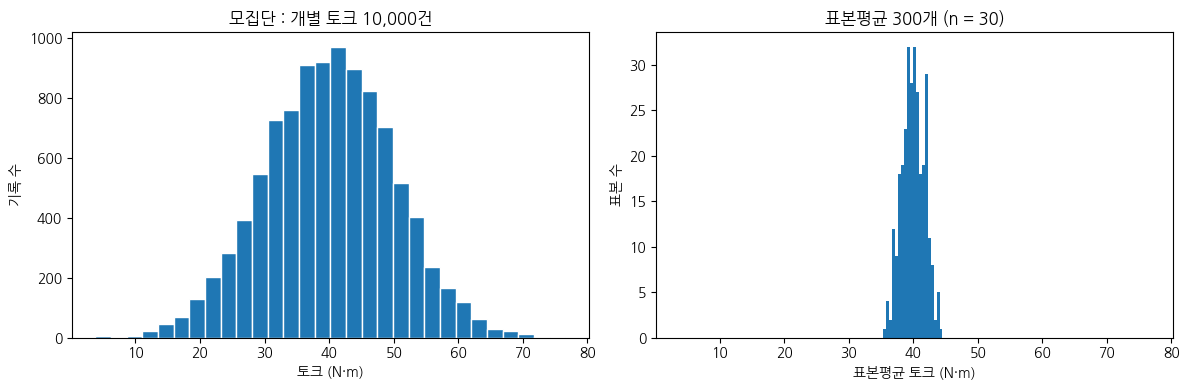

In [ ]:
# [예제] 토크 30건 표본을 300번 뽑아 표본평균 300개를 모으고, 개별 토크 분포와 표본평균 분포를 나란히 그린다
# 표본평균 300개의 평균·표준편차를 모평균, σ ÷ √30 과 비교한다

population = data["Torque [Nm]"]               # 실습용 모집단 : 토크 10,000건 (앞 실습과 같은 값)
population_mean = population.mean()            # 모평균 μ
population_sd = population.std(ddof=0)         # 모표준편차 σ (분모 N)

sample_means = []                                                          # 표본평균을 모을 빈 리스트
for i in range(300):                                                       # 300번 반복
    repeat_sample = population.sample(n=30, replace=False, random_state=100 + i)   # 반복마다 다른 30건 (random_state 100 ~ 399)
    sample_means.append(repeat_sample.mean())                              # append : 리스트 끝에 표본평균을 하나씩 추가
sample_means = pd.Series(sample_means)                                     # 평균·표준편차를 바로 구하도록 Series 로 바꾼다

print("표본평균 300개의 평균:", round(sample_means.mean(), 2), "N·m")       # 표본평균 분포의 중심
print("표본평균 300개의 표준편차:", round(sample_means.std(), 2), "N·m")    # 표본평균 분포의 퍼짐 (= 실제로 잰 표준오차)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)               # 1행 2열 그림. sharex=True : 두 칸의 가로축 범위를 같게 맞춤
axes[0].hist(population, bins=30, edgecolor="white")                       # 왼쪽 : 개별 토크 10,000건의 히스토그램
axes[0].set(title="모집단 : 개별 토크 10,000건", xlabel="토크 (N·m)", ylabel="기록 수")
axes[1].hist(sample_means, bins=20)                                        # 오른쪽 : 표본평균 300개의 히스토그램
axes[1].set(title="표본평균 300개 (n = 30)", xlabel="표본평균 토크 (N·m)", ylabel="표본 수")
plt.tight_layout()                                                         # 제목·축 이름이 겹치지 않게 간격 조정
plt.show()

### 원자료가 치우친 경우 : 회전속도

회전속도(`Rotational speed [rpm]`)는 대부분 1,400 ~ 1,600 rpm에 모여 있고 큰 값 쪽으로 꼬리가 긴 분포다(왜도 약 2.0). 이런 자료에서 표본 크기 n을 1 · 5 · 30으로 바꿔 표본평균을 1,000개씩 모으면, n이 커질수록 표본평균의 분포가 어떻게 달라지는지 볼 수 있다. n = 1은 한 건씩 뽑은 것이라 원자료의 분포와 같다.

n = 1 / 왜도: 1.97 / 표준오차(SE): 181.6 rpm
n = 5 / 왜도: 0.86 / 표준오차(SE): 81.3 rpm
n = 30 / 왜도: 0.3 / 표준오차(SE): 32.8 rpm


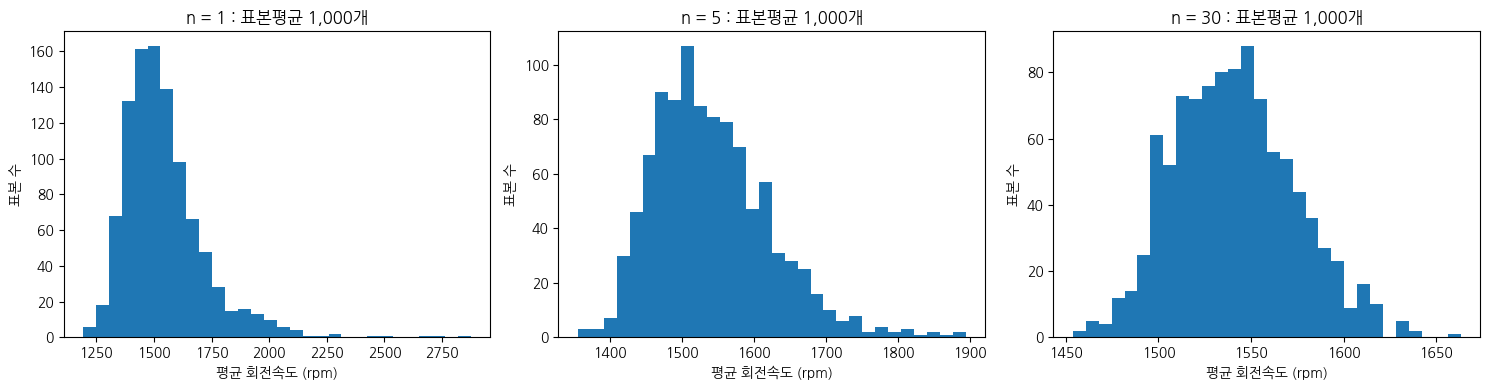

In [ ]:

# [예제] 회전속도 : 표본 크기 1, 5, 30에 따른 표본평균 분포 비교
# 표본 크기가 커질수록 왜도와 표준오차가 어떻게 변하는지 확인한다.

speed = data["Rotational speed [rpm]"]     # 원본 회전속도 데이터
sizes = [1, 5, 30]                         # 한 번에 뽑을 표본 크기

fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 그래프 3개를 가로로 배치

for k in range(3):
    size = sizes[k]                         # 표본 크기 : 1, 5, 30
    speed_means = []                        # 표본평균을 저장할 빈 리스트

    for i in range(1000):                   # 표본추출을 1,000번 반복
        sample = speed.sample(
            n=size,                         # 한 번에 size개 추출
            replace=False,                  # 한 번 추출할 때 중복 없이 선택
            random_state=i                  # 반복마다 난수 시드 변경
        )
        speed_means.append(sample.mean())   # 추출한 표본의 평균 저장

    speed_means = pd.Series(speed_means)     # 표본평균 1,000개를 Series로 변환

    # 왜도 : 0에 가까울수록 좌우 대칭
    # 표준오차 : 표본평균들이 얼마나 흩어져 있는지 나타냄
    print("n =", size,
          "/ 왜도:", round(speed_means.skew(), 2),
          "/ 표준오차(SE):", round(speed_means.std(), 1), "rpm")

    axes[k].hist(speed_means, bins=30)      # 표본평균 1,000개의 분포
    axes[k].set(
        title="n = " + str(size) + " : 표본평균 1,000개",
        xlabel="평균 회전속도 (rpm)",
        ylabel="표본 수"
    )

plt.tight_layout()                          # 그래프 간격 조정
plt.show()


## 4. 표준편차와 표준오차

**표준편차**(SD, s)는 개별 값이 평균에서 흩어진 정도이고, **표준오차**(SE, Standard Error)는 표본을 반복해 뽑을 때 표본평균이 달라지는 정도다. 실제 분석에서는 표본을 한 번만 뽑으므로, 그 표본의 s로 표준오차를 추정한다.

| 비교 항목 | 표준편차 (SD, s) | 표준오차 (SE) |
|---|---|---|
| 측정 대상 | 개별 관측값의 산포 | 표본평균의 산포 (표본을 반복해 뽑을 때) |
| 식 | s = √( Σ(xᵢ − x̄)² ÷ (n − 1) ) | SE = s ÷ √n |
| 표본 크기 증가 시 | 자료 자체의 산포라 작아지지 않는다 | √n이 커져 작아진다 |
| 주요 활용 | 공정 변동, 규격과 비교, 이상값 확인 | 평균 추정의 정밀도, 신뢰구간, 검정 |

**표본오차와 표준오차** : 표본오차(x̄ − μ)는 이번 표본에서 실제로 생긴 차이로, μ를 모르므로 실제 분석에서는 계산할 수 없다. 표준오차는 그런 차이가 보통 얼마나 되는지를 s와 n으로 계산한 크기다.

**보고서의 ± 표기** : "평균 ± 값"으로 쓸 때는 ± 뒤가 SD인지 SE인지 반드시 함께 적는다. 데이터 자체의 흩어진 정도는 SD로, 평균 추정의 정확도는 SE로 보고한다.

| 함수 | 기능 |
|---|---|
| `x.std(ddof=1)` | 표본표준편차. 분모 n − 1. NumPy의 기본값은 `ddof=0`이라 반드시 적는다 (pandas `std()`는 기본이 `ddof=1`) |
| `stats.sem(x)` | 표준오차 s ÷ √n을 바로 계산한다 (sem = standard error of the mean) |

공식 문서 : [scipy.stats.sem](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html) · [numpy.std](https://numpy.org/doc/stable/reference/generated/numpy.std.html)

In [ ]:
# [예제] 공정시간 30건 (단위 : 분)
x = np.array([53, 43, 60, 61, 44, 52, 52, 62, 54, 46, 52, 53, 52, 45, 50,
              59, 60, 43, 50, 51, 55, 52, 52, 54, 52, 48, 54, 50, 59, 46])
print("표본평균:", round(x.mean(), 2), "분")
print("표본표준편차 (ddof=1):", round(x.std(ddof=1), 2), "분")
print("표준오차 s ÷ √n:", round(x.std(ddof=1) / np.sqrt(len(x)), 2), "분")
print("표준오차 stats.sem:", round(stats.sem(x), 2), "분")

s = pd.Series(x)
print("pandas : 평균", round(s.mean(), 2), "/ 표준편차", round(s.std(), 2), "/ 표준오차", round(s.sem(), 2))

표본평균: 52.13 분
표본표준편차 (ddof=1): 5.27 분
표준오차 s ÷ √n: 0.96 분
표준오차 stats.sem: 0.96 분
pandas : 평균 52.13 / 표준편차 5.27 / 표준오차 0.96


In [ ]:
# [실습]
# 상황 : 토크 30건을 한 번 뽑아, 이 표본 하나로 평균 토크를 추정한다.
# 토크 30건(random_state=10)의 표본평균, 표본표준편차, 표준오차는 얼마인가? 표준오차는 직접 계산한 값과 stats.sem 을 비교하시오.
# 표본은 sample, 표본 크기는 n, 표본평균은 sample_mean, 표준오차는 se 라는 이름에 담는다



## 5. 신뢰구간

**점추정**은 모수를 값 하나로 추정하는 것이고(예 : 모평균을 표본평균 52.13분으로 추정), **구간추정**은 모수가 포함될 것으로 기대되는 범위를 하한과 상한으로 제시하는 것이다. 이 범위를 **신뢰구간**(Confidence Interval)이라 한다.

**신뢰구간의 구조** : 추정값 ± 임계값 × 표준오차

| 구성 | 뜻 | 공정시간 30건 예 |
|---|---|---|
| 추정값 | 표본에서 계산한 통계량 (평균이면 x̄) | 52.13분 |
| 임계값 | 표준오차에 곱해 신뢰구간의 폭을 결정하는 숫자 | 2.045 (t분포, 자유도 29, 95%) |
| 표준오차 | 추정값이 표본추출로 흔들리는 크기 | 0.962분 |
| 오차한계 | 임계값 × 표준오차. 구간의 반폭 | 1.97분 |

**t분포를 쓰는 이유** : 모표준편차 σ를 모르고 표본표준편차 s로 추정하면 불확실성이 늘어나, 95%에서도 임계값이 1.96보다 커진다. 임계값은 **자유도**(df = n − 1)와 신뢰수준으로 정해진다. 표본이 작을수록 임계값이 커져 구간이 넓어진다.

**신뢰수준과 구간 폭** : 신뢰수준을 높이면(90% → 95% → 99%) 임계값이 커져 구간이 넓어진다. 신뢰수준은 계산하기 전에 정하며, 보통 95%를 쓴다.

**95%의 의미** : 같은 방법으로 표본추출과 계산을 반복하면, 만들어진 구간의 약 95%가 실제 모평균을 포함한다. 신뢰구간은 모평균이 있을 만한 범위이며, 개별 데이터가 들어가는 범위가 아니다.

| 함수 | 기능 |
|---|---|
| `stats.t.ppf(0.975, df=n - 1)` | t분포(자유도 n − 1)에서 왼쪽부터 97.5%가 쌓인 지점. 평균의 95% 신뢰구간 임계값 (n = 30이면 2.045). 가운데 95%를 남기면 양쪽 꼬리가 2.5%씩이라 0.975를 넣는다 |
| `stats.norm.ppf(0.975)` | 표준정규분포에서 같은 97.5% 지점 (1.960) |
| `stats.t.interval(0.95, df=n - 1, loc=평균, scale=SE)` | 신뢰수준 0.95를 넣어 신뢰구간을 한 번에 계산한다 |

`ppf`에는 왼쪽부터 쌓인 확률(0.975)을, `interval`에는 신뢰수준(0.95)을 넣는다.

같은 0.975 지점이라도 분포가 달라 값이 다르다. 평균의 신뢰구간은 모표준편차 σ를 모르고 표본의 s로 추정하므로 t분포 임계값을 쓴다. 이 자료는 모평균과 σ를 알고 있지만, 실제 분석처럼 모른다고 보고 s로 계산한다. 자유도가 커지면 t 임계값은 1.960에 가까워진다.

공식 문서 : [scipy.stats.t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html) · [scipy.stats.norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) · [NIST : Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)

In [ ]:
# [예제] 공정시간 30건으로 모평균의 95% 신뢰구간 구하기
n_x = len(x)
se_x = stats.sem(x)
t_star = stats.t.ppf(0.975, df=n_x - 1)
print("표준오차:", round(se_x, 3), "/ 자유도:", n_x - 1, "/ t 임계값:", round(t_star, 3))

# 1) 직접 계산 : 추정값 ± 임계값 × 표준오차
print("직접 계산:", round(x.mean() - t_star * se_x, 2), "~", round(x.mean() + t_star * se_x, 2))

# 2) t.interval 로 한 번에
low, high = stats.t.interval(0.95, df=n_x - 1, loc=x.mean(), scale=se_x)
print("t.interval:", round(low, 2), "~", round(high, 2))

표준오차: 0.962 / 자유도: 29 / t 임계값: 2.045
직접 계산: 50.17 ~ 54.1
t.interval: 50.17 ~ 54.1


In [ ]:
# [실습]
# 상황 : 앞에서 뽑은 토크 30건 표본(sample) 하나로 모평균 토크의 범위를 추정한다.
# sample_mean 과 se 로 95% 신뢰구간을 stats.t.interval 로 구해 ci_low, ci_high 에 담으시오.




In [ ]:
# [실습]
# 상황 : 신뢰구간을 읽는 두 가지 방법이 맞는지 확인한다. 모평균을 아는 상황 (실제 분석에서는 모평균을 모른다)
# 1) 모평균 population_mean(39.99 N·m)은 신뢰구간 ci_low ~ ci_high 안에 있는가?
# 2) 표본 sample 30건 중 신뢰구간 안에 들어가는 토크 값은 몇 개인가?


## 6. 표본 크기와 정밀도

SE = s ÷ √n이므로 s가 같을 때 n이 커지면 표준오차가 작아지고 신뢰구간도 좁아진다. 표준오차는 √n에 반비례하므로, 표준오차를 절반으로 줄이려면 표본을 2배가 아니라 **4배**로 늘려야 한다.

| 표본 크기 | s = 10일 때 표준오차 | 비교 |
|---|---|---|
| n = 25 | 10 ÷ 5 = 2.00 | 기준 |
| n = 100 | 10 ÷ 10 = 1.00 | n 4배 → SE 절반 |
| n = 400 | 10 ÷ 20 = 0.50 | n 16배 → SE 4분의 1 |

표본을 늘리면 정밀도(구간 폭)는 좋아진다.

In [ ]:
# [예제] 표준편차가 10으로 같을 때 표본 크기에 따른 표준오차
for size in [25, 100, 400]:
    print("n =", size, "/ SE =", round(10 / np.sqrt(size), 2))

n = 25 / SE = 2.0
n = 100 / SE = 1.0
n = 400 / SE = 0.5


In [ ]:
# [예제] 토크를 25건 · 100건 · 400건 뽑아(random_state=42) 표준편차, 표준오차, 95% 신뢰구간과 구간 폭을 비교한다

for size in [25, 100, 400]:
    size_sample = population.sample(n=size, replace=False, random_state=42)
    size_se = stats.sem(size_sample)
    low, high = stats.t.interval(0.95, df=size - 1, loc=size_sample.mean(), scale=size_se)
    print("n =", size, "/ SD", round(size_sample.std(), 2), "/ SE", round(size_se, 2),
          "/ 95% 신뢰구간", round(low, 2), "~", round(high, 2), "/ 폭", round(high - low, 2))

n = 25 / SD 6.97 / SE 1.39 / 95% 신뢰구간 37.74 ~ 43.49 / 폭 5.75
n = 100 / SD 8.09 / SE 0.81 / 95% 신뢰구간 38.61 ~ 41.82 / 폭 3.21
n = 400 / SD 9.6 / SE 0.48 / 95% 신뢰구간 39.44 ~ 41.33 / 폭 1.89


## 7. 추정 결과를 문장으로 보고하기

앞에서 사용한 토크 30건 표본으로 점추정과 구간추정 결과를 한 문장으로 정리한다. 표본 크기, 표본평균, 표준오차, 신뢰수준과 신뢰구간을 모두 넣는다.

In [ ]:
# [실습]
# 상황 : 설비팀에 평균 토크 추정 결과를 보고한다. 숫자만 나열하지 않고 무엇을 어떤 신뢰수준으로 추정했는지 한 문장으로 쓴다.
# 1) 보고 문장에 들어갈 n, 표본평균, SE, 95% 신뢰구간을 출력하시오.
# 2) 출력한 값으로 아래 보고 문장의 빈칸을 채우시오.
#    운전 기록 ___건의 평균 토크는 ___ N·m(SE ___ N·m)이며, 95% 신뢰수준에서 모평균 토크를 ___ ~ ___ N·m로 추정한다.

print("n:", n)                                                         # 앞에서 구한 값들을 그대로 출력
print("표본평균:", round(sample_mean, 2), "N·m")                        # 점추정
print("SE:", round(se, 2), "N·m")                                     # 표준오차 : 표본평균이 표본마다 보통 얼마나 달라지는지 (추정의 정밀도)
print("95% 신뢰구간:", round(ci_low, 2), "~", round(ci_high, 2), "N·m")   # 구간추정


# - 운전 기록 30건의 평균 토크는 40.79 N·m(SE 1.77 N·m)이며, 95% 신뢰수준에서 모평균 토크를 37.18 ~ 44.41 N·m로 추정한다.

NameError: name 'n' is not defined

## 8. 정리

| 개념 | 뜻 | 코드 |
|---|---|---|
| 모집단 · 모수 | 결론을 적용할 대상 전체와 그 특성값 (μ, σ, p) | — |
| 표본 · 통계량 | 실제로 조사한 일부와 거기서 계산한 값 (x̄, s, p̂) | `data.sample(n=, replace=False, random_state=)` |
| 표본추출 방법 | 단순무작위 · 계통 · 층화 · 군집. 방법은 대표성에, 크기는 정밀도에 영향 | `sample` · `iloc[시작::간격]` · `concat` · `isin` |
| 표본추출 변동 | 표본을 다시 뽑으면 표본평균이 달라지는 것 | — |
| 중심극한정리 | n이 커질수록 **표본평균의 분포**가 정규분포에 가까워진다 | — |
| 표준편차 (SD) | 개별 값의 퍼짐 | `x.std(ddof=1)` |
| 표준오차 (SE) | 표본평균의 퍼짐. s ÷ √n | `stats.sem(x)` |
| 신뢰구간 | 추정값 ± 임계값 × 표준오차 | `stats.t.ppf(0.975, df=n-1)` · `stats.t.interval(0.95, ...)` |
| 95% 신뢰수준 | 같은 방법을 반복하면 만든 구간의 약 95%가 모평균을 포함한다 | — |

순서
1) 모집단(결론을 적용할 범위)과 분석 단위를 먼저 정한다
2) 대표성과 독립성을 갖춘 방법으로 표본을 뽑는다
3) 표본평균(점추정)과 표준편차, 표준오차를 구한다
4) 신뢰수준을 정하고 신뢰구간(구간추정)을 구한다
5) 보고할 때는 n, 표본평균, SE 또는 SD(어느 쪽인지 명시), 신뢰구간을 함께 적는다

공식 문서 : [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html) · [NIST : Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)